In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

Load Iris dataset

In [19]:
import pandas as pd

df = pd.read_csv("/content/Automobile_data.csv")

display(df.head())
print(df.shape)

print("\nMissing values:")
print(df.isnull().sum())

# Convert selected columns to numeric
numeric_cols = [
    "price", "horsepower", "engine-size", "curb-weight",
    "city-mpg", "highway-mpg", "wheel-base", "length",
    "width", "height"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
sns.set_theme(style="whitegrid")

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.4,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.4,8.0,115,5500,18,22,17450


(205, 26)

Missing values:
symboling            0
normalized-losses    0
make                 0
fuel-type            0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               0
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
dtype: int64


Bar plot: Number of cars by make

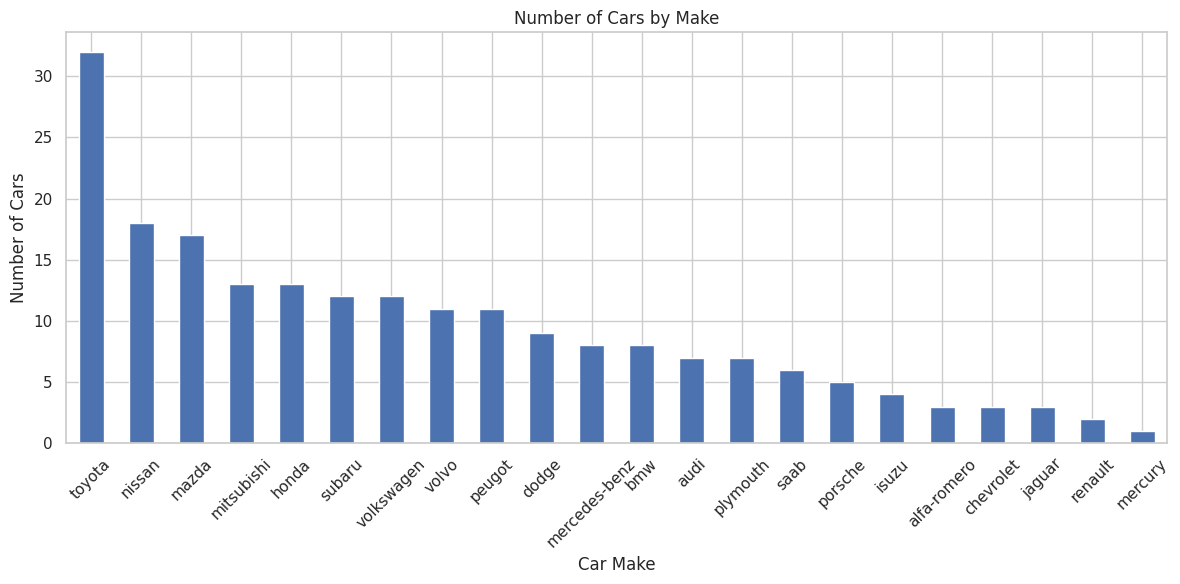

In [20]:
plt.figure(figsize=(12, 6))
df["make"].value_counts().plot(kind="bar")
plt.title("Number of Cars by Make")
plt.xlabel("Car Make")
plt.ylabel("Number of Cars")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Histogram: Distribution of car prices

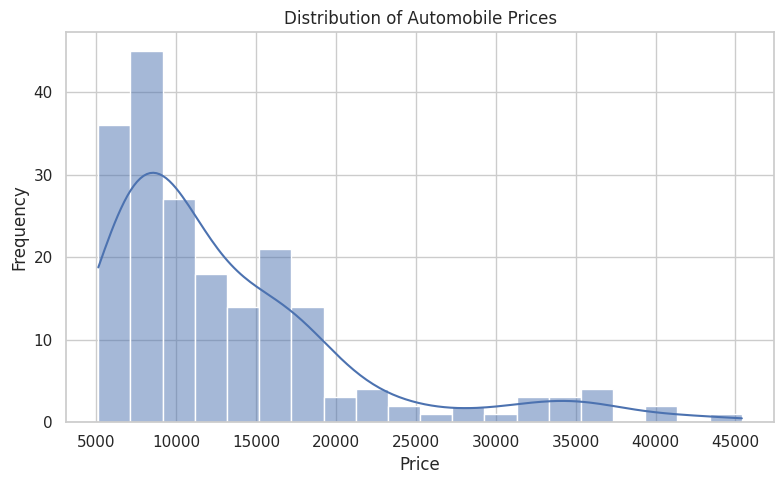

In [21]:
plt.figure(figsize=(8, 5))
sns.histplot(df["price"].dropna(), bins=20, kde=True)
plt.title("Distribution of Automobile Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

Box plot: Price by body style

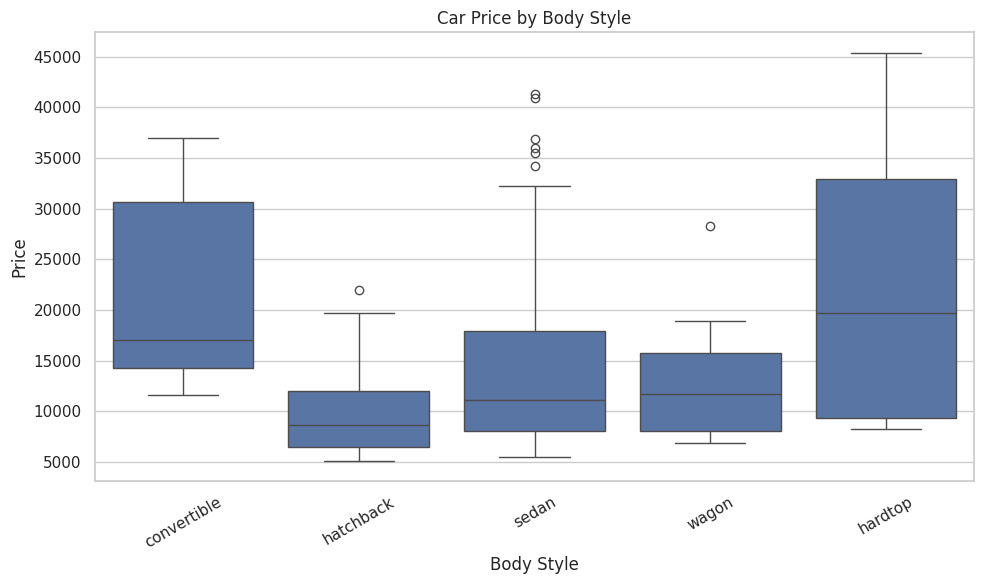

In [22]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="body-style", y="price")
plt.title("Car Price by Body Style")
plt.xlabel("Body Style")
plt.ylabel("Price")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Scatter plot: Engine size vs price

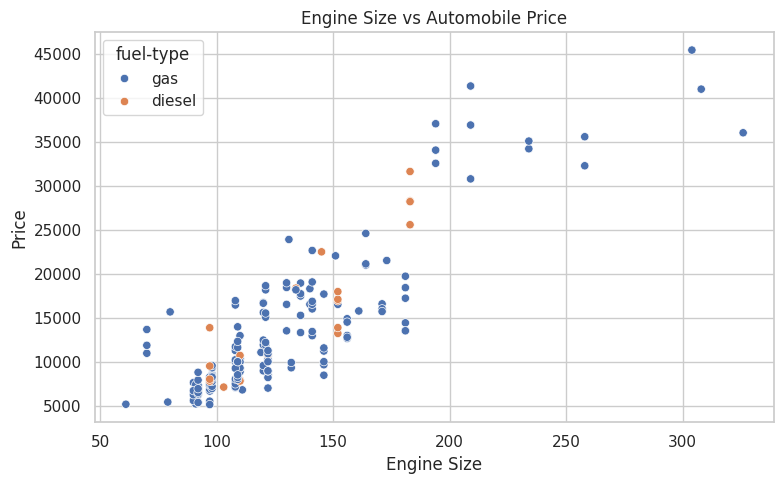

In [23]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df, x="engine-size", y="price", hue="fuel-type"
)
plt.title("Engine Size vs Automobile Price")
plt.xlabel("Engine Size")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

Line plot: Average price by horsepower

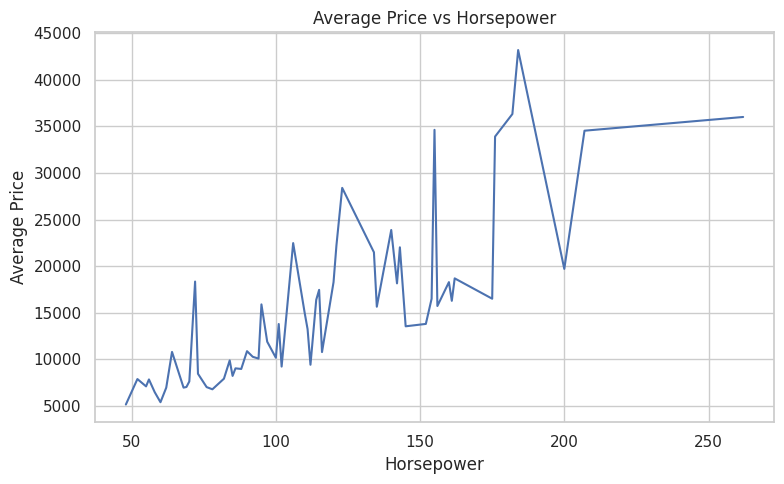

In [24]:
avg_price = (
    df.dropna(subset=["horsepower", "price"])
      .groupby("horsepower", as_index=False)["price"]
      .mean()
      .sort_values("horsepower")
)

plt.figure(figsize=(8, 5))
sns.lineplot(data=avg_price, x="horsepower", y="price")
plt.title("Average Price vs Horsepower")
plt.xlabel("Horsepower")
plt.ylabel("Average Price")
plt.tight_layout()
plt.show()


Count plot: Cars by fuel type

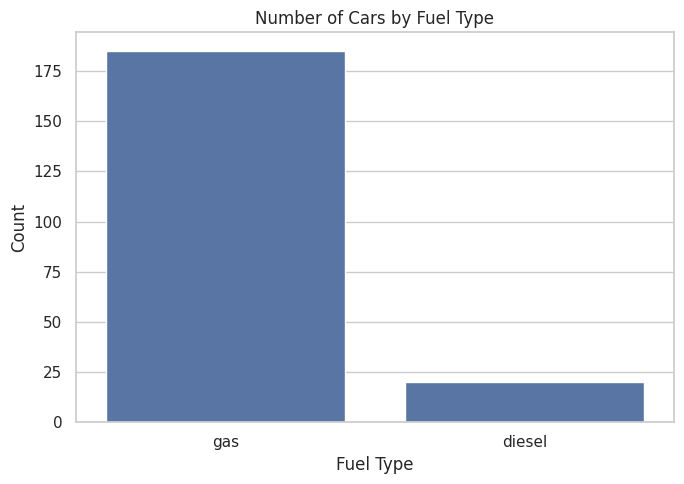

In [26]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="fuel-type")
plt.title("Number of Cars by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


Heatmap: Correlation between numerical features

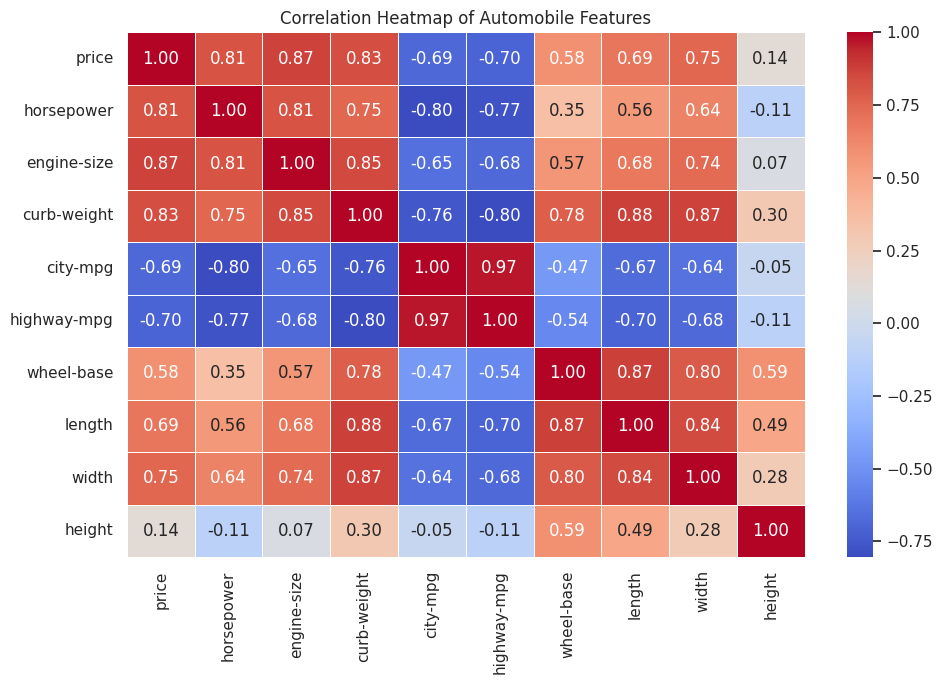

In [27]:
plt.figure(figsize=(10, 7))
correlation = df[numeric_cols].corr()
sns.heatmap(
    correlation, annot=True, cmap="coolwarm",
    fmt=".2f", linewidths=0.5
)
plt.title("Correlation Heatmap of Automobile Features")
plt.tight_layout()
plt.show()


Pair plot: Relationships between selected features

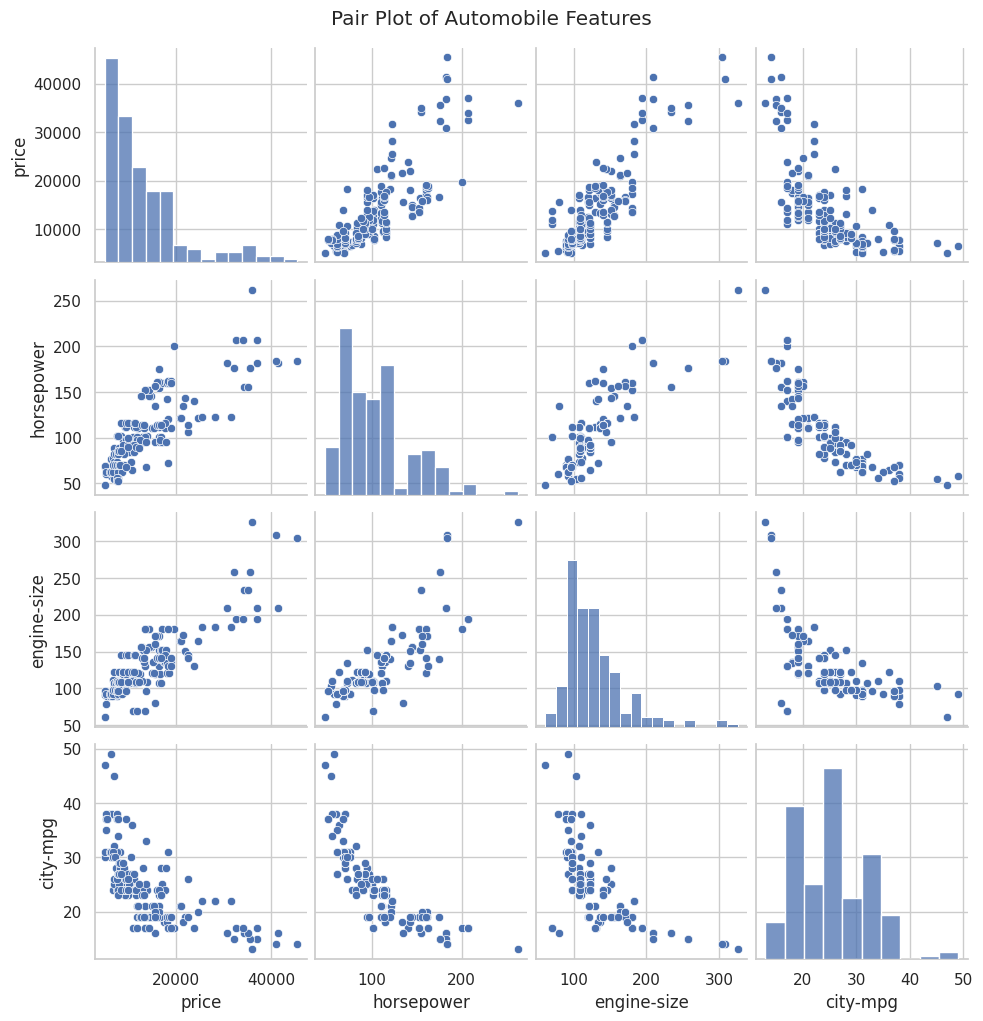

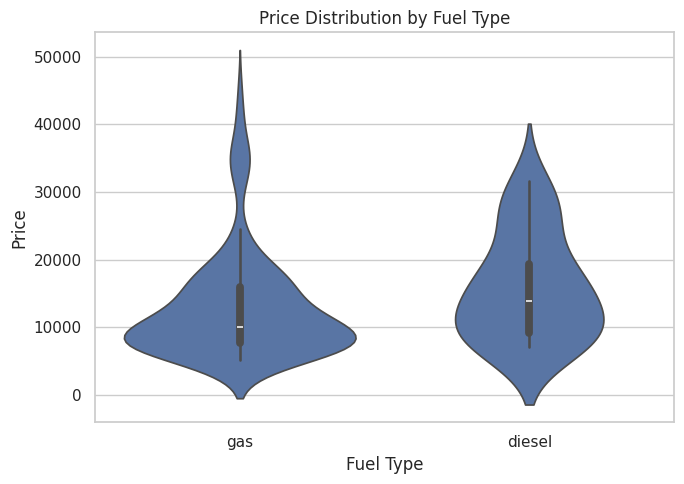

In [28]:
pair_data = df[
    ["price", "horsepower", "engine-size", "city-mpg"]
].dropna()

sns.pairplot(pair_data)
plt.suptitle("Pair Plot of Automobile Features", y=1.02)
plt.show()

# 9. Violin plot: Price distribution by fuel type
plt.figure(figsize=(7, 5))
sns.violinplot(data=df, x="fuel-type", y="price")
plt.title("Price Distribution by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

Regression plot: Horsepower vs price

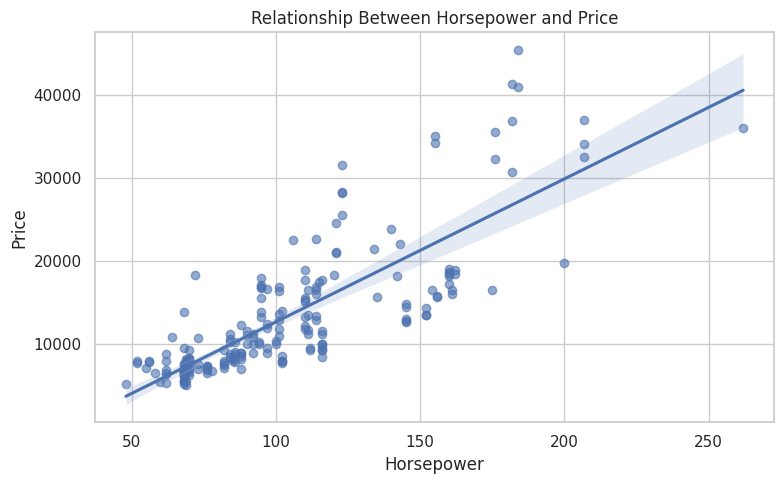

In [29]:
plt.figure(figsize=(8, 5))
sns.regplot(
    data=df, x="horsepower", y="price",
    scatter_kws={"alpha": 0.6}
)
plt.title("Relationship Between Horsepower and Price")
plt.xlabel("Horsepower")
plt.ylabel("Price")
plt.tight_layout()
plt.show()
